### Constraints
- Predict the age of the abalone with accuracy of +/- 3 years for 90% of predictions
- Limit Size & Memory

### Roles
- Tree Ensembles: Alia
- Knn: Yaqoub
- SVR: Alasdair 
- Validation & Pipeline: Mrugaya
- Benchmarking & Testing: Rayan


In [2]:
#@title Run this first: course helper module (ai4_tools). Double-click to see the code.
# ENG4200 / ENG5338 helper module. Source of truth is notebooks/ai4_tools.py in the
# course repository. Do not edit here: edit there and rerun build_toolcell.py, or the
# change is lost the next time the notebook is reissued.
_AI4_TOOLS_SOURCE = r'''
"""
ai4_tools: runtime reporting and cost measurement for ENG4200 / ENG5338.

Why this exists. The courseworks ask for computational efficiency: training time,
inference latency and memory footprint. A number timed on one runtime and compared
against a number timed on another is not evidence, so every timing this module produces
carries the runtime it was measured on.

Use it like this:

    show_runtime()                       # once, at the top of every notebook
    r = benchmark(model, Xtr, ytr, Xte, yte)
    table = ResultsTable(); table.add("logistic regression", r); table.df()
    decision("Stratified 5-fold", "3.4% positives, plain k-fold can empty a fold", r)

Standard library plus numpy only. pandas, scikit-learn, torch and psutil are all optional
and are used if present. Written for Python 3.8 and later so it runs on Colab, on the lab
machines and on a student laptop without changes.
"""

import gc
import importlib.util
import os
import platform
import statistics
import subprocess
import sys
import threading
import time
import tracemalloc
from contextlib import contextmanager

__all__ = [
    "runtime_info", "runtime_line", "show_runtime",
    "timed", "benchmark", "peak_memory",
    "ResultsTable", "decision",
    "register_sections", "check", "check_raises", "scorecard", "reset_checks",
]

_MB = 1024.0 * 1024.0


# ----------------------------------------------------------------------------------
# Runtime description
# ----------------------------------------------------------------------------------

def _have(name):
    """True if a module is importable, without importing it."""
    try:
        return importlib.util.find_spec(name) is not None
    except (ImportError, ValueError):
        return False


def _cpu_model():
    system = platform.system()
    try:
        if system == "Linux":
            with open("/proc/cpuinfo") as fh:
                for line in fh:
                    if line.startswith("model name"):
                        return line.split(":", 1)[1].strip()
        elif system == "Darwin":
            out = subprocess.check_output(
                ["sysctl", "-n", "machdep.cpu.brand_string"],
                stderr=subprocess.DEVNULL, timeout=5,
            )
            return out.decode().strip()
    except Exception:
        pass
    return platform.processor() or platform.machine() or "unknown CPU"


def _total_ram_gb():
    try:
        import psutil  # noqa: F401
        return psutil.virtual_memory().total / (1024 ** 3)
    except Exception:
        pass
    try:
        return (os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES")) / (1024 ** 3)
    except (ValueError, OSError, AttributeError):
        return None


def _gpu_state():
    """(has_gpu, name). Reports what torch can actually use, not what is installed."""
    if "torch" not in sys.modules and not _have("torch"):
        return False, "torch not installed"
    try:
        import torch
        if torch.cuda.is_available():
            return True, torch.cuda.get_device_name(0)
        if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
            return True, "Apple MPS"
        return False, "none attached"
    except Exception as exc:
        return False, "torch present but unusable ({})".format(type(exc).__name__)


def runtime_info():
    """Everything that makes one timing comparable with another, as a dict."""
    has_gpu, gpu_name = _gpu_state()
    ram = _total_ram_gb()
    return {
        "platform": "Google Colab" if _have("google.colab") else platform.system(),
        "python": platform.python_version(),
        "cpu": _cpu_model(),
        "cores": os.cpu_count(),
        "ram_gb": round(ram, 1) if ram else None,
        "accelerator": gpu_name if has_gpu else "CPU only",
        "has_gpu": has_gpu,
    }


def runtime_line(info=None):
    """The one line that goes with every number you report. Paste it into the report."""
    i = info or runtime_info()
    ram = "{} GB".format(i["ram_gb"]) if i["ram_gb"] else "RAM unknown"
    return "{} | {} ({} cores, {}) | {} | Python {}".format(
        i["platform"], i["cpu"], i["cores"], ram, i["accelerator"], i["python"]
    )


def show_runtime():
    """Run this once at the top of every notebook. Returns the line so you can keep it."""
    info = runtime_info()
    line = runtime_line(info)
    print("Runtime:", line)
    if info["has_gpu"] and info["platform"] == "Google Colab":
        print(
            "\nA GPU is attached. scikit-learn cannot use it, so for Tutorials 1 to 4 it\n"
            "buys you nothing and spends a rationed allowance you will want in November\n"
            "for Lab 2 and CW3. Set Runtime > Change runtime type > CPU unless you are\n"
            "running PyTorch."
        )
    elif info["has_gpu"]:
        print("\nAn accelerator is available. scikit-learn will not use it; only PyTorch will.")
    return line


# ----------------------------------------------------------------------------------
# Timing
# ----------------------------------------------------------------------------------

@contextmanager
def timed(label="elapsed", quiet=False):
    """with timed('fit'): model.fit(X, y)   ->   seconds land in .seconds"""
    class _T:
        seconds = None
    t = _T()
    start = time.perf_counter()
    try:
        yield t
    finally:
        t.seconds = time.perf_counter() - start
        if not quiet:
            print("{}: {:.4f} s".format(label, t.seconds))


def _clone(model):
    try:
        from sklearn.base import clone
        return clone(model)
    except Exception:
        import copy
        return copy.deepcopy(model)


def _median_of(fn, repeats):
    """One warm-up run that is thrown away, then `repeats` timed runs. Median, not mean:
    a single slow run caused by something else on the machine should not move the number."""
    fn()
    samples = []
    for _ in range(repeats):
        gc.collect()
        start = time.perf_counter()
        fn()
        samples.append(time.perf_counter() - start)
    return statistics.median(samples), min(samples)


def benchmark(model, X_train, y_train, X_test, y_test=None, scorer=None,
              repeats=3, label=None, measure_memory=False):
    """Fit and predict cost for one model, on one runtime, in a form you can tabulate.

    Returns a dict with fit_s, predict_s, predict_ms_per_1k and the runtime line.
    `predict_ms_per_1k` is the one CW3 asks for, because inference latency has to be
    per unit of work or it just measures how big your test set happened to be.

    Note the difference from %timeit, which is fine for a demonstration but prints to the
    screen instead of returning a value you can put in a results table.
    """
    n_train = len(X_train)
    n_test = len(X_test)

    fit_median, fit_best = _median_of(lambda: _clone(model).fit(X_train, y_train), repeats)

    fitted = _clone(model).fit(X_train, y_train)
    pred_median, pred_best = _median_of(lambda: fitted.predict(X_test), repeats)

    score = None
    if y_test is not None:
        try:
            score = scorer(y_test, fitted.predict(X_test)) if scorer else fitted.score(X_test, y_test)
        except Exception as exc:
            print("Could not score this model: {}".format(exc))

    result = {
        "model": label or type(model).__name__,
        "score": score,
        "fit_s": fit_median,
        "fit_s_best": fit_best,
        "predict_s": pred_median,
        "predict_ms_per_1k": (pred_median / n_test) * 1000.0 * 1000.0 if n_test else None,
        "n_train": n_train,
        "n_test": n_test,
        "repeats": repeats,
        "runtime": runtime_line(),
    }

    if measure_memory:
        mb, metric = peak_memory(lambda: _clone(model).fit(X_train, y_train))
        result["peak_mem_mb"] = mb
        result["mem_metric"] = metric

    return result


# ----------------------------------------------------------------------------------
# Memory
# ----------------------------------------------------------------------------------

def _rss_bytes():
    """Current resident set size of this process, or None if we cannot read it.

    Resident set size, not the Python heap. scikit-learn's trees and torch's tensors are
    allocated in C, which tracemalloc never sees, so a tracemalloc figure for a random
    forest comes out roughly two orders of magnitude too small.
    """
    try:
        import psutil
        return psutil.Process().memory_info().rss
    except Exception:
        pass
    try:
        with open("/proc/self/statm") as fh:
            return int(fh.read().split()[1]) * os.sysconf("SC_PAGE_SIZE")
    except Exception:
        return None


def peak_memory(fn, interval=0.01):
    """Peak memory used by fn(), as (megabytes, which_metric).

    The second value is not decoration. Three different quantities can come back here
    depending on the runtime, and they are not interchangeable:

      GPU device memory      measured by torch when a CUDA device is attached
      host process RSS       peak resident memory minus the baseline, sampled while fn runs
      host Python heap       tracemalloc, the last resort, and an undercount for anything
                             that allocates in C, which includes scikit-learn and torch

    A table that does not say which one it holds cannot be compared with anyone else's.
    So the metric travels with the number.
    """
    has_gpu, _ = _gpu_state()
    if has_gpu:
        try:
            import torch
            if torch.cuda.is_available():
                torch.cuda.synchronize()
                torch.cuda.reset_peak_memory_stats()
                fn()
                torch.cuda.synchronize()
                return torch.cuda.max_memory_allocated() / _MB, "GPU device memory (torch.cuda)"
        except Exception:
            pass

    gc.collect()
    baseline = _rss_bytes()
    if baseline is not None:
        peak = [baseline]
        stop = threading.Event()

        def _sample():
            while not stop.is_set():
                current = _rss_bytes()
                if current is not None and current > peak[0]:
                    peak[0] = current
                stop.wait(interval)

        watcher = threading.Thread(target=_sample, daemon=True)
        watcher.start()
        try:
            fn()
        finally:
            stop.set()
            watcher.join(timeout=1.0)
        return max(peak[0] - baseline, 0) / _MB, "host process RSS (peak minus baseline)"

    gc.collect()
    tracemalloc.start()
    try:
        fn()
        _, peak_traced = tracemalloc.get_traced_memory()
    finally:
        tracemalloc.stop()
    return peak_traced / _MB, "host Python heap (tracemalloc, undercounts C allocations)"


# ----------------------------------------------------------------------------------
# Results table and decision log
# ----------------------------------------------------------------------------------

class ResultsTable:
    """Accumulates benchmark() rows. Every row keeps the runtime it was measured on, so
    a table assembled across two sessions cannot silently mix a CPU run with a GPU one."""

    def __init__(self):
        self.rows = []

    def add(self, label, result=None, **extra):
        if result is None:
            result = {}
        row = dict(result)
        row["model"] = label
        row.update(extra)
        self.rows.append(row)
        return self

    def df(self, columns=("model", "score", "fit_s", "predict_ms_per_1k")):
        try:
            import pandas as pd
        except ImportError:
            return self.rows
        frame = pd.DataFrame(self.rows)
        keep = [c for c in columns if c in frame.columns]
        rest = [c for c in frame.columns if c not in keep and c != "runtime"]
        return frame[keep + rest]

    def runtimes(self):
        """The distinct runtimes in this table. More than one means the timings in it
        are not comparable with each other, and the table needs splitting or rerunning."""
        return sorted({r.get("runtime") for r in self.rows if r.get("runtime")})

    def check(self):
        seen = self.runtimes()
        if len(seen) > 1:
            print("Warning: this table mixes {} different runtimes. The scores are still\n"
                  "valid but the timings are not comparable across rows:".format(len(seen)))
            for s in seen:
                print("  -", s)
            return False
        return True


_SECTIONS = {}
_CHECKS = []


def register_sections(titles):
    """register_sections({1: "Python basics", 2: "NumPy"}) so the scorecard can name them."""
    _SECTIONS.clear()
    _SECTIONS.update(titles)


def reset_checks():
    del _CHECKS[:]


def _section_of(label):
    head = str(label).split(None, 1)[0]
    try:
        return int(head.split(".")[0])
    except (ValueError, IndexError):
        return 0


def check(label, condition, hint=None):
    """Assertion with a hint instead of a traceback.

    An AssertionError on its own tells you nothing useful, so a failed check says what
    was expected and what to try, and the notebook keeps running so the later exercises
    are still attemptable.

        check("2.1 shape is 3 by 4", a.shape == (3, 4), "np.reshape takes the new shape")

    `condition` is normally a boolean, which means Python evaluates it before check() ever
    sees it: if the expression itself raises, the student gets their own traceback at the
    call site, which is the right thing to happen. The bool() is still guarded because
    comparing two numpy arrays gives an array, and calling bool() on it raises rather than
    returning False.

    Pass a zero-argument callable instead when the expression is expected to raise and you
    want the failure recorded rather than thrown:

        check("3.4 raises on a bad column", lambda: df["nope"], "KeyError is correct here")
    """
    if callable(condition):
        try:
            condition = condition()
        except Exception as exc:
            _CHECKS.append({"label": str(label), "section": _section_of(label), "passed": False})
            print("FAIL  {}".format(label))
            print("      raised {}: {}".format(type(exc).__name__, exc))
            if hint:
                print("      hint: {}".format(hint))
            return False
    try:
        passed = bool(condition)
    except Exception as exc:
        passed = False
        hint = "{} (comparison gave {}, not a single True or False)".format(
            hint or "", type(exc).__name__).strip()

    _CHECKS.append({"label": str(label), "section": _section_of(label), "passed": passed})
    if passed:
        print("PASS  {}".format(label))
    else:
        print("FAIL  {}".format(label))
        if hint:
            print("      hint: {}".format(hint))
    return passed


def check_raises(label, fn, expected=Exception, hint=None):
    """Passes when fn() raises `expected`. For demonstrating what going wrong looks like.

    Without this, a notebook that wants to show a student a KeyError has to contain a
    check that fails on purpose, which then sits on their scorecard telling them to redo a
    section they got right.

        check_raises("4.3 missing column", lambda: df["nope"], KeyError)
    """
    try:
        fn()
    except expected as exc:
        _CHECKS.append({"label": str(label), "section": _section_of(label), "passed": True})
        print("PASS  {}  (raised {} as expected: {})".format(label, type(exc).__name__, exc))
        return True
    except Exception as exc:
        _CHECKS.append({"label": str(label), "section": _section_of(label), "passed": False})
        print("FAIL  {}  (raised {}, expected {})".format(label, type(exc).__name__, expected.__name__))
        if hint:
            print("      hint: {}".format(hint))
        return False
    _CHECKS.append({"label": str(label), "section": _section_of(label), "passed": False})
    print("FAIL  {}  (nothing was raised, expected {})".format(label, expected.__name__))
    if hint:
        print("      hint: {}".format(hint))
    return False


def milestone(n, of=5, title=None):
    """A banner wide enough to read from a few metres, for the lab clinics.

    A demonstrator walking a room of eighty laptops cannot tell who is stuck, so the lab
    notebooks print one of these after each milestone's checks and students are asked to
    leave it on screen. Reads the checks already recorded for section `n`, so it adds no
    new judgement of its own. Returns True when every check in the section passed.
    """
    checks = [c for c in _CHECKS if c["section"] == n]
    passed = bool(checks) and all(c["passed"] for c in checks)
    title = title or _SECTIONS.get(n, "Milestone {}".format(n))
    bar = "=" * 62
    print(bar)
    print("   M I L E S T O N E   {}   of {}          {}".format(
        n, of, "P A S S E D" if passed else "N O T   Y E T"))
    print("   {}".format(title))
    if not passed:
        outstanding = [c["label"] for c in checks if not c["passed"]]
        print("   outstanding: {}".format(", ".join(outstanding) if outstanding
                                          else "run the cells above first"))
    print(bar)
    return passed


def scorecard(next_step="Tutorial 1"):
    """Per-section pass counts, and the list of sections worth going back to.

    `next_step` names what the student is getting ready for, so the closing line reads
    "You are ready for Lab 1a" rather than always pointing at Tutorial 1.
    """
    if not _CHECKS:
        print("No checks have run yet. Run the cells above first.")
        return {}

    sections = {}
    for c in _CHECKS:
        got = sections.setdefault(c["section"], {"passed": 0, "total": 0, "failed": []})
        got["total"] += 1
        if c["passed"]:
            got["passed"] += 1
        else:
            got["failed"].append(c["label"])

    print("Scorecard")
    print("-" * 62)
    revisit = []
    for num in sorted(sections):
        got = sections[num]
        title = _SECTIONS.get(num, "Section {}".format(num))
        flag = "" if got["passed"] == got["total"] else "   <- revisit"
        print("{:<34} {}/{} passed{}".format(title[:34], got["passed"], got["total"], flag))
        if got["passed"] != got["total"]:
            revisit.append(title)
            for lab in got["failed"]:
                print("      {}".format(lab))
    print("-" * 62)
    total = sum(g["total"] for g in sections.values())
    passed = sum(g["passed"] for g in sections.values())
    print("{}/{} checks passed".format(passed, total))
    if revisit:
        print("\nBefore {}, go back over: {}".format(next_step, ", ".join(revisit)))
    else:
        print("\nNothing outstanding. You are ready for {}.".format(next_step))
    return {"passed": passed, "total": total, "revisit": revisit}


_LOG = []


def decision(choice, why, cost=None):
    """One decision log entry: what I chose, why, what it cost, and on what.

    By the coursework deadline these entries are the skeleton of the report's
    justification section, which is where most of the marks are.
    """
    if isinstance(cost, dict):
        bits = []
        if cost.get("fit_s") is not None:
            bits.append("fit {:.3f} s".format(cost["fit_s"]))
        if cost.get("predict_ms_per_1k") is not None:
            bits.append("inference {:.2f} ms per 1000 rows".format(cost["predict_ms_per_1k"]))
        if cost.get("peak_mem_mb") is not None:
            bits.append("peak memory {:.1f} MB ({})".format(cost["peak_mem_mb"], cost.get("mem_metric", "unspecified")))
        cost_text = ", ".join(bits) if bits else "not measured"
        runtime = cost.get("runtime") or runtime_line()
    else:
        cost_text = str(cost) if cost is not None else "not measured"
        runtime = runtime_line()

    entry = {"choice": choice, "why": why, "cost": cost_text, "runtime": runtime}
    _LOG.append(entry)

    print("Decision {}".format(len(_LOG)))
    print("  Chose:   {}".format(choice))
    print("  Because: {}".format(why))
    print("  Cost:    {}".format(cost_text))
    print("  Runtime: {}".format(runtime))
    return entry


def decision_log():
    """Every entry so far, as a DataFrame if pandas is available."""
    try:
        import pandas as pd
        return pd.DataFrame(_LOG)
    except ImportError:
        return list(_LOG)


if __name__ == "__main__":
    show_runtime()
'''

with open("ai4_tools.py", "w", encoding="utf-8") as _fh:
    _fh.write(_AI4_TOOLS_SOURCE.lstrip("\n"))
import importlib as _importlib
import ai4_tools
ai4_tools = _importlib.reload(ai4_tools)
print("ai4_tools ready ({} lines written to ai4_tools.py)".format(_AI4_TOOLS_SOURCE.count("\n")))

ai4_tools ready (566 lines written to ai4_tools.py)


In [3]:
import os
import argparse
import csv
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ai4_tools as ai4
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.metrics import make_scorer, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, train_test_split, RandomizedSearchCV, cross_validate, validation_curve
from sklearn.metrics import make_scorer,  mean_squared_error, root_mean_squared_error
from sklearn.datasets import make_regression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.inspection import permutation_importance
from scipy.stats import uniform, randint


warnings.filterwarnings("ignore", category=UserWarning)
RUNTIME = ai4.show_runtime()

Runtime: Windows | Intel64 Family 6 Model 140 Stepping 1, GenuineIntel (8 cores, 15.8 GB) | CPU only | Python 3.12.4


# Pipeline Section : Mrugaya

In [5]:
RANDOM_STATE = 42
TEST_SIZE = 0.2
AGE_OFFSET = 1.5
TARGET = "rings"
CATEGORICAL_FEATURES = ["sex"]
NUMERIC_FEATURES = [
    "length",
    "diameter",
    "height",
    "whole_weight",
    "shucked_weight",
    "viscera_weight",
    "shell_weight",
]
def calculate_age(rings):
    """Convert the number of rings to age in years."""
    return rings + AGE_OFFSET

# Load the data from the CSV file and preprocess it
data = pd.read_csv("abalone.csv")
x = data.drop(columns=[TARGET])
y = data[TARGET]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

In [6]:
# 1. PREPROCESSING PIPELINE
# Assuming column 0 is 'Sex' (categorical) and columns 1-8 are 
# the numerical physical measurements of the abalone.
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), [0]),  # Encodes Sex (M, F, I)
        ('num', StandardScaler(), slice(1, 9))                 # Scales measurements
    ]
)

#When you build your model pipelines, plug the preprocessor object at the very beginning of your pipeline 
#before your estimator so that scaling and encoding happen safely inside the CV loop.

# 2. SHARED CROSS-VALIDATION PROTOCOL
# The brief requires every model to use the exact same folds. 
shared_cv = KFold(n_splits=5, shuffle=True, random_state=42) 
#pls use shared_cv for all your cross-validation loops 
#so we are evaluating models on the exact same data splits

# 3. CUSTOM CONSTRAINT METRIC (+/- 3 years for 90% of cases)
def within_tolerance_score(y_true, y_pred):
    """
    Calculates the fraction of predictions that fall within 
    +/- 3 units (years/rings) of the true value.
    """
    abs_errors = np.abs(y_true - y_pred)
    fraction_within = np.mean(abs_errors <= 3.0)
    return fraction_within

constraint_scorer = make_scorer(within_tolerance_score, greater_is_better=True)


# Model Section

## Knn: Yaqoub

In [ ]:
from sklearn.neighbors import KNeighborsRegressor

knn_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', KNeighborsRegressor(n_neighbors=5))
])

In [ ]:
from sklearn.model_selection import validation_curve

neighbors = [3, 5, 7, 9, 11, 15, 21]

train_scores, val_scores = validation_curve(
    knn_pipeline,
    x_train,
    y_train,
    param_name="regressor__n_neighbors",
    param_range=neighbors,
    cv=shared_cv,
    scoring=constraint_scorer,
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(neighbors, train_mean, "o-",
        label="Training score")

ax.plot(neighbors, val_mean, "s-",
        label="5-fold validation score")

ax.fill_between(
    neighbors,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.2,
    label="Validation +/- 1 SD"
)

ax.set_xlabel("Number of neighbours (k)")
ax.set_ylabel("Fraction within +/- 3 rings")
ax.set_title("Validation curve: kNN neighbours")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

In [ ]:
best_knn = grid_search.best_estimator_

knn_metrics = ai4.benchmark(
    model=best_knn,
    X_train=x_train,
    y_train=y_train,
    X_test=x_train,
    y_test=y_train,
    scorer=within_tolerance_score,
    measure_memory=True,
    label="Tuned kNN"
)

table_knn = ai4.ResultsTable()
table_knn.add("Tuned kNN", knn_metrics)
display(table_knn.df())



from sklearn.model_selection import GridSearchCV


param_grid = {
    'regressor__n_neighbors': [3, 5, 7, 9, 11, 15, 21],
    'regressor__weights': ['uniform', 'distance']
}


grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=shared_cv,
    scoring={
        'within_3': constraint_scorer,
        'mae': 'neg_mean_absolute_error'
    },
    refit='within_3',
    return_train_score=True,
    n_jobs=-1
)

with ai4.timed("kNN Hyperparameter Tuning"):
    grid_search.fit(x_train, y_train)

best_index = grid_search.best_index_
best_knn = grid_search.best_estimator_

best_cv_score = grid_search.best_score_ * 100
best_cv_mae = -grid_search.cv_results_[
    'mean_test_mae'
][best_index]

print("Best parameters:", grid_search.best_params_)
print(f"Best CV within +/- 3 rings: {best_cv_score:.2f}%")
print(f"CV MAE for selected model: {best_cv_mae:.4f}")

In [ ]:
if 'experiments' not in globals():
    experiments = {}

experiments['kNN_tuned'] = best_knn

knn_summary = {
    'Model': 'Tuned kNN',
    'Neighbours': grid_search.best_params_[
        'regressor__n_neighbors'
    ],
    'Weights': grid_search.best_params_[
        'regressor__weights'
    ],
    'CV within +/- 3 (%)': round(best_cv_score, 2),
    'CV MAE': round(best_cv_mae, 4),
    'Training time (s)': round(knn_metrics['fit_s'], 4),
    'Prediction time (ms/1k)': round(
        knn_metrics['predict_ms_per_1k'], 3
    ),
    'Peak memory increase (MB)': round(
        knn_metrics['peak_mem_mb'], 4
    )
}

display(pd.DataFrame([knn_summary]))


## Tree Ensembles: Alia

In [9]:
hgb_pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', HistGradientBoostingRegressor(random_state=42)) 
])

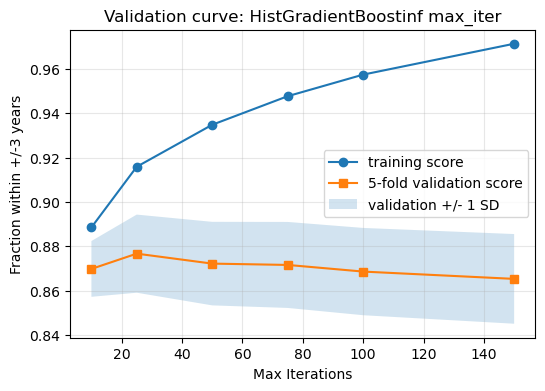

In [10]:
iter_values = [10, 25, 50, 75, 100, 150]
train_scores, validation_scores = validation_curve(
    hgb_pipeline,
    x_train,
    y_train,
    param_name="model__max_iter",
    param_range=iter_values,
    cv=shared_cv,
    scoring=constraint_scorer,
    n_jobs=-1,
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
validation_mean = validation_scores.mean(axis=1)
validation_std = validation_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(iter_values, train_mean, "o-", label="training score")
ax.plot(iter_values, validation_mean, "s-", label="5-fold validation score")
ax.fill_between(
    iter_values,
    validation_mean - validation_std,
    validation_mean + validation_std,
    alpha=0.2,
    label="validation +/- 1 SD",
)
#ax.set_xscale("log")
ax.set_xlabel("Max Iterations")
ax.set_ylabel("Fraction within +/-3 years")
ax.set_title("Validation curve: HistGradientBoostinf max_iter")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [11]:



from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import HistGradientBoostingRegressor, AdaBoostRegressor, GradientBoostingRegressor
from scipy.stats import uniform, randint
import time






#Hyperparameters to be tuned
hgb_parameters = {
    'model__learning_rate': uniform(0.01, 1), 
    'model__max_iter': randint(20, 110),
    'model__max_leaf_nodes': randint(10, 50), 
    'model__min_samples_leaf': randint(1, 50),
    'model__l2_regularization': uniform(0, 10), 
}

hgb_TUNE = "histgradboost"
start_hgb = time.time() # start timer for hyperparameter tuning

# Perform RandomizedSearchCV for HistGradientBoostingRegressor
hgb_random_search = RandomizedSearchCV(
    estimator=hgb_pipeline,
    param_distributions=hgb_parameters,
    n_iter=50, 
    scoring=constraint_scorer,
    cv=shared_cv,
    n_jobs=-1,
    return_train_score=True,
)

# Begin hyperparameter tuning
hgb_random_search.fit(x_train, y_train)
end_hgb = time.time() # end timer for hyperparameter tuning

#Use best hyperparameter values to benchmark
hgb_metrics = ai4.benchmark(
    model=hgb_random_search.best_estimator_,
    X_train=x_train,
    y_train=y_train,
    X_test=x_test,
    y_test=y_test,
    scorer=within_tolerance_score,
    measure_memory=True,
    label="HistGradientBoostingRegressor (Tuned)",
)

#Model Performance Evaluation
table_hgb = ai4.ResultsTable()



table_hgb.add("HistGradientBoostingRegressor (Tuned)", hgb_metrics)
display(table_hgb.df())

# Store tuned model

if 'experiments' not in globals():
    experiments={}

#hgb_vector_number = random_search.best_estimator_.named_steps["HGB"].n_support_[0]
experiments[hgb_TUNE + ", tuned"] = hgb_random_search.best_estimator_

#Report best hyperparameters and time taken for tuning
print(f"Best score: {hgb_random_search.best_score_:.3f} years")
print(f"Total runtime for hyperparameter tuning: {end_hgb - start_hgb:.2f} seconds")

print("Best hyperparameters:")
for parameter, value in hgb_random_search.best_params_.items():
    print(f"{parameter}: {value}")


# MAE and RMSE for the best model
y_pred_hgb = hgb_random_search.predict(x_test)
print(f"MAE: {mean_absolute_error(y_test, y_pred_hgb):.3f} years")
print(f"RMSE: {root_mean_squared_error(y_test, y_pred_hgb):.3f} years")

  File "C:\Users\aliab\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\aliab\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\aliab\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\aliab\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


,model,score,fit_s,predict_ms_per_1k,fit_s_best,predict_s,n_train,n_test,repeats,peak_mem_mb,mem_metric
0,HistGradientBoostingRegressor (Tuned),0.881579,0.357403,10.732536,0.329877,0.008972,3341,836,3,0.121094,host process RSS (peak minus baseline)


Best score: 0.877 years
Total runtime for hyperparameter tuning: 12.53 seconds
Best hyperparameters:
model__l2_regularization: 6.079310090709554
model__learning_rate: 0.06415686292189747
model__max_iter: 30
model__max_leaf_nodes: 39
model__min_samples_leaf: 5
MAE: 1.575 years
RMSE: 2.269 years


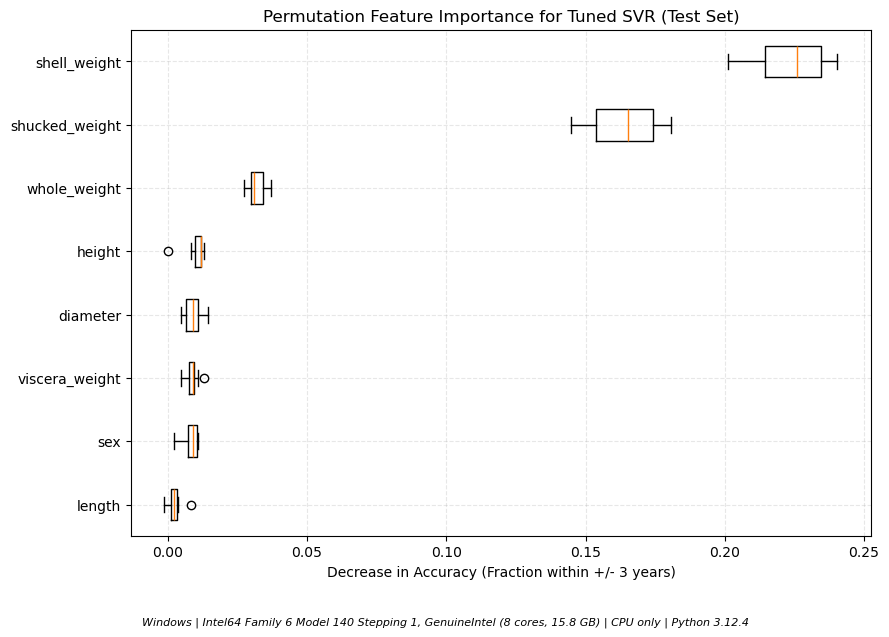

In [12]:
from sklearn.inspection import permutation_importance

perm_importance = permutation_importance(
    hgb_random_search.best_estimator_, 
    x_test, 
    y_test, 
    scoring=constraint_scorer, 
    n_repeats=10, 
    random_state=42, 
    n_jobs=-1
)

feature_names = x_test.columns.to_numpy()
sorted_idx = perm_importance.importances_mean.argsort()

#sorted_idx = perm_importance.importances_mean.argsort()

fig, ax = plt.subplots(figsize=(9, 6))
ax.boxplot(
    perm_importance.importances[sorted_idx].T,
    vert=False,
    labels=feature_names[sorted_idx]
)
ax.set_xlabel("Decrease in Accuracy (Fraction within +/- 3 years)")
ax.set_title("Permutation Feature Importance for Tuned SVR (Test Set)")
ax.grid(alpha=0.3, linestyle="--")

fig.text(0.5, -0.05, ai4.runtime_line(), ha="center", fontsize=8, style="italic")
plt.tight_layout()
plt.show()

In [13]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

best_hgb = hgb_random_search.best_estimator_
y_pred = best_hgb.predict(x_test)

final_hgb_export = {
    "Model Name": "Tuned HistGradientBoostingRegressor",
    "Test MAE": round(mean_absolute_error(y_test, y_pred), 3),
    "Test RMSE": round(root_mean_squared_error(y_test, y_pred), 3),
    "Custom Score (+/- 3 yrs)": round(hgb_metrics["score"], 3),
    "Training Time (s)": round(hgb_metrics["fit_s"], 3),
    "Prediction Time (ms/1k rows)": round(hgb_metrics["predict_ms_per_1k"], 3),
    "Memory Footprint (MB)": round(hgb_metrics["peak_mem_mb"], 3),
}

print("--- Final HGB Metrics for Group Compilation ---")
for key, val in final_hgb_export.items():
    print(f"{key}: {val}")

--- Final HGB Metrics for Group Compilation ---
Model Name: Tuned HistGradientBoostingRegressor
Test MAE: 1.575
Test RMSE: 2.269
Custom Score (+/- 3 yrs): 0.882
Training Time (s): 0.357
Prediction Time (ms/1k rows): 10.733
Memory Footprint (MB): 0.121


## SVR: Alasdair

In [15]:
RANDOM_STATE = 42
TEST_SIZE = 0.2
AGE_OFFSET = 1.5
TARGET = "rings"
CATEGORICAL_FEATURES = ["sex"]
NUMERIC_FEATURES = [
    "length",
    "diameter",
    "height",
    "whole_weight",
    "shucked_weight",
    "viscera_weight",
    "shell_weight",
]
def calculate_age(rings):
    """Convert the number of rings to age in years."""
    return rings + AGE_OFFSET

# Load the data from the CSV file and preprocess it
data = pd.read_csv("abalone.csv")
x = data.drop(columns=[TARGET])
y = data[TARGET]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('svr', SVR(kernel='rbf'))])

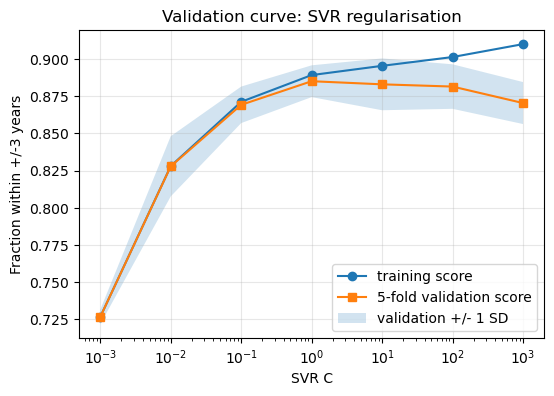

In [16]:
c_values = np.logspace(-3, 3, 7)
train_scores, validation_scores = validation_curve(
    pipeline,
    x_train,
    y_train,
    param_name="svr__C",
    param_range=c_values,
    cv=shared_cv,
    scoring=constraint_scorer,
    n_jobs=-1,
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
validation_mean = validation_scores.mean(axis=1)
validation_std = validation_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(c_values, train_mean, "o-", label="training score")
ax.plot(c_values, validation_mean, "s-", label="5-fold validation score")
ax.fill_between(
    c_values,
    validation_mean - validation_std,
    validation_mean + validation_std,
    alpha=0.2,
    label="validation +/- 1 SD",
)
ax.set_xscale("log")
ax.set_xlabel("SVR C")
ax.set_ylabel("Fraction within +/-3 years")
ax.set_title("Validation curve: SVR regularisation")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [17]:
parameter_grid = {
        "svr__C": np.logspace(1, 3, 4),         
        "svr__gamma": np.logspace(-3, 1, 5),     
        "svr__epsilon": [1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0],
    }
search = GridSearchCV(pipeline, parameter_grid, scoring={'constraint_scorer': constraint_scorer, 'neg_mean_squared_error': make_scorer(mean_squared_error, greater_is_better=False)}, refit='constraint_scorer', cv=shared_cv, n_jobs=-1, return_train_score=True)
search.fit(x_train, y_train)
svr_metrics = ai4.benchmark(model=search.best_estimator_, X_train=x_train, y_train=y_train, X_test=x_test, y_test=y_test, scorer=within_tolerance_score, label="Tuned SVR Pipeline", measure_memory=True)
table = ai4.ResultsTable()
table.add("SVR", svr_metrics)
display(table.df())
vector_number = search.best_estimator_.named_steps["svr"].n_support_[0]
print(f"Number of support vectors: {vector_number}")
print("Best hyperparameters:")
for parameter, value in search.best_params_.items():
    print(f"{parameter}: {value}")

,model,score,fit_s,predict_ms_per_1k,fit_s_best,predict_s,n_train,n_test,repeats,peak_mem_mb,mem_metric
0,SVR,0.87799,0.522448,92.033732,0.509157,0.07694,3341,836,3,15.777344,host process RSS (peak minus baseline)


Number of support vectors: 1176
Best hyperparameters:
svr__C: 1000.0
svr__epsilon: 1.5
svr__gamma: 0.01


TypeError: Axes.boxplot() got an unexpected keyword argument 'tick_labels'

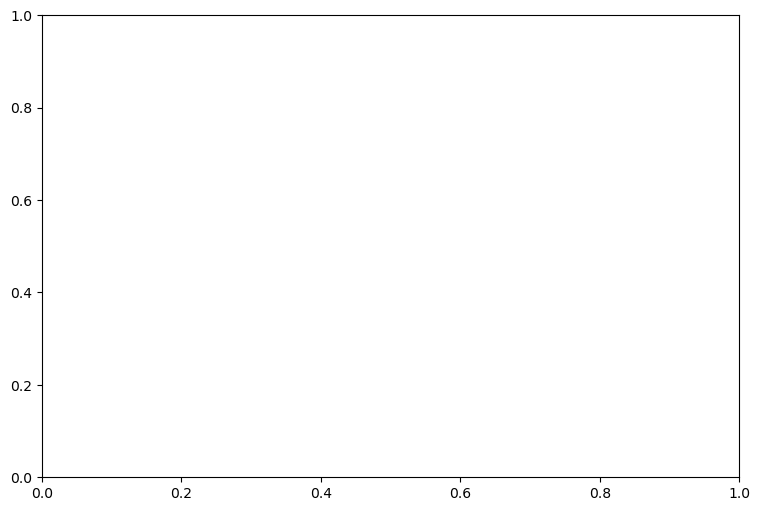

In [18]:
from sklearn.inspection import permutation_importance

perm_importance = permutation_importance(
    search.best_estimator_, 
    x_test, 
    y_test, 
    scoring=constraint_scorer, 
    n_repeats=10, 
    random_state=RANDOM_STATE, 
    n_jobs=-1
)

feature_names = x_test.columns.to_numpy()
sorted_idx = perm_importance.importances_mean.argsort()

sorted_idx = perm_importance.importances_mean.argsort()

fig, ax = plt.subplots(figsize=(9, 6))
ax.boxplot(
    perm_importance.importances[sorted_idx].T,
    vert=False,
    tick_labels=feature_names[sorted_idx]
)
ax.set_xlabel("Decrease in Accuracy (Fraction within +/- 3 years)")
ax.set_title("Permutation Feature Importance for Tuned SVR (Test Set)")
ax.grid(alpha=0.3, linestyle="--")

fig.text(0.5, -0.05, ai4.runtime_line(), ha="center", fontsize=8, style="italic")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

best_svr = search.best_estimator_
y_pred = best_svr.predict(x_test)

final_svr_export = {
    "Model Name": "Tuned SVR",
    "Test MAE": round(mean_absolute_error(y_test, y_pred), 3),
    "Test RMSE": round(root_mean_squared_error(y_test, y_pred), 3),
    "Custom Score (+/- 3 yrs)": round(svr_metrics["score"], 3),
    "Training Time (s)": round(svr_metrics["fit_s"], 3),
    "Prediction Time (ms/1k rows)": round(svr_metrics["predict_ms_per_1k"], 3),
    "Memory Footprint (MB)": round(svr_metrics["peak_mem_mb"], 3),
    "Support Vector Count": best_svr.named_steps['svr'].n_support_[0]
}

print("--- Final SVR Metrics for Group Compilation ---")
for key, val in final_svr_export.items():
    print(f"{key}: {val}")

# Benchmarking & Testing: Rayan